# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Соснило Богдан Тарасович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 12      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 12: Хмельницький, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_хмельницький


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    t0 = time.time()
    b0 = cache_bytes()
    gdf_raw = getter()
    g = clean(gdf_raw)
    g.to_parquet(path, index=False)
    COST[name] = {'спосіб':'живий запит',
                  'записів': len(g),
                      'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
    return g
    # ----- ВАШ КОД: живий запит -----
    # 1) запам'ятайте cache_bytes() і час ДО виклику getter()
    # 2) викличте getter(), проженіть результат через clean(), збережіть у path
    # 3) запишіть у COST[name] спосіб 'живий запит', записів, передано_МБ,
    #    файл_МБ і секунд
    raise NotImplementedError('напишіть гілку живого запиту')

In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 98.2 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 12373 | ребер 35338


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [9]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.036,0.209
heritage,знімок,79,0.0,0.047,0.055
stations,знімок,7,0.0,0.033,0.035
amenities,знімок,278,0.0,0.063,0.067
мережа walk,знімок,47711,0.0,2.445,0.231


Висновок: якщо брати до прикладу два різних рядка(наприклад boundary та heritage), то ми можемо побачити, що читання знімка відбувається майже в 1000 разів швидше(0.129 проти 102.766), на цей час також впливає загруженість overpass. Також можемо побачити, що для знімків передано 0 МБ(бралось з локальної пам'яті), а для живих запитів певний трафік був.

> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
# ----- ВАШ КОД -----
mask = heritage['historic'].notna() | heritage['tourism'].isin(TOURISM_OK)

cand = heritage[mask & heritage['name'].notna()].copy()

cand = cand.reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', mask.sum())
print('з них мають name       :', len(cand))

усього у шарі heritage : 79
підходять за тегами    : 79
з них мають name       : 56


In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial    19
monument     7
aircraft     1

=== tourism ===
tourism
artwork       10
museum         9
attraction     6
viewpoint      3
gallery        1

типи геометрії: {'Point': 53, 'Polygon': 3}


Висновок: відкинули 23 рядка, оскільки без значення стовпця 'name' ми не можемо нормально оперувати цими даними, взагалі невідомо, чи це справді якась пам'ятка, чи просто помилка в датасеті, тому було прийняте рішення їх не враховувати

> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

In [12]:
cand.head()

,element,id,geometry,historic,memorial,name,name:en,name:uk,wikidata,wikipedia,...,fee,operator,museum,access,building,contact:facebook,addr:housenumber,addr:postcode,building:levels,roof:shape
0,node,530817814,POINT (26.98516 49.4221),memorial,statue,Тарас Шевченко,Taras Hryhorovych Shevchenko,Тарас Григорович Шевченко,Q12138442,uk:Пам'ятник Тарасові Шевченку (Хмельницький),...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,node,1201343514,POINT (26.98312 49.42161),memorial,<NA>,Воїнам-інтернаціоналістам,<NA>,Воїнам-інтернаціоналістам,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,node,1466764590,POINT (26.96881 49.41078),memorial,<NA>,Солдат,<NA>,Солдат,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,node,1998588629,POINT (26.9934 49.42005),memorial,<NA>,Іван Якович Франко,Ivan Yakovych Franko,Іван Якович Франко,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,node,2026459025,POINT (27.01908 49.43481),monument,<NA>,Меморіал Слави,<NA>,Меморіал Слави,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [13]:
metric = cand.to_crs(32635)

cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),metric.area.values, 0.0) 

cand['wiki'] = cand['wikidata'].notna() | (cand['wikipedia'].notna() if 'wikipedia' in cand.columns else False)

name_cols = [c for c in cand.columns if str(c).startswith('name:')]
cand['n_lang'] = cand[name_cols].notna().sum(axis=1)

cand['score'] = (
    cand['wiki'].rank(pct=True) * 0.4 + 
    cand['n_lang'].rank(pct=True) * 0.4 + 
    cand['area_m2'].rank(pct=True) * 0.2
)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))

кандидатів   : 56
мають wiki   : 16


Висновок: обрав такі ваги, оскільки вікіпедія та переклад на інші мови доволі показові, це означає, що пам'ятка важлива та популярнач

### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [14]:
N_SMALL, N_LARGE = 10, 30
top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10 = top_score.head(N_SMALL)

top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)

overlap = len(set(top10['name']).intersection(set(top_naive['name'])))

print('перетин: %d з %d' % (overlap, N_SMALL))

display(pd.DataFrame({
    'за вашим критерієм': list(top10['name']),
    'за площею': list(top_naive['name'])
}))


перетин: 3 з 10


,за вашим критерієм,за площею
0,Хмельницький обласний художній музей,Пам'ятник Богданові Хмельницькому
1,Тарас Шевченко,Музей проскурівського підпілля
2,Вічний вогонь,Богдан Хмельницький
3,Ботанічний сад ХНУ,Тарас Шевченко
4,Пам'ятник Богданові Хмельницькому,Воїнам-інтернаціоналістам
5,Богдан Хмельницький,Солдат
6,Музей історії міста Хмельницького,Іван Якович Франко
7,Меморіал жертвам Голокосту,Меморіал Слави
8,Героям Небесної Сотні,Полеглим односельцям
9,Віра Надія Любов,Жертвам Чорнобиля


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [15]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

pairs = close_pairs(top_score, limit_m=60)
print("Близькі пари (менше 60 м):")
for i, j, d in pairs:
    name1 = top_score['name'].iloc[i]
    name2 = top_score['name'].iloc[j]
    print(f"{name1} --- {name2} (відстань: {d:.1f} м)")


Близькі пари (менше 60 м):
Ангел Скорботи --- Ейфелева вежа (відстань: 41.6 м)


Висновок: Хоча відстань між двома пам'ятками 40 м, я їх залишу, оскільки це дві різні пам'ятки, тому їх обох окремо треба відвідати

---
## 4. Старт: вокзал, і прив'язка точок до графа

In [16]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 7
                              name  railway        building
0                     Хмельницький  station            <NA>
1             Кам'янецький Переїзд     halt            <NA>
2                          Гречани  station            <NA>
3                           Ракове     halt            <NA>
4                    Речовий ринок     halt            <NA>
5  Залізничний вокзал Хмельницький     <NA>   train_station
6                             <NA>  station  transportation


In [17]:

station = stations[stations['name'].str.contains('Хмельницький', case=False, na=False)].head(1)

print('старт:', station['name'].iloc[0])

старт: Хмельницький


In [18]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 12373 вузлів, 34903 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [19]:
def check_snap(points, ids, dist, label):
    n_points = len(points)
    n_nodes = len(set(ids))
    
    print(f"\n--- {label} ---")
    print(f"Точок: {n_points} | Зайнято унікальних вузлів: {n_nodes}")
    
    print(f"Відстань (точка -> вузол): медіана = {np.median(dist):.1f} м, макс = {np.max(dist):.1f} м")
    
    if n_nodes < n_points:
        print("Знайдено точки, що злиплись (однаковий вузол):")
        
        node_map = {}
        for i, node_id in enumerate(ids):
            name = points['name'].iloc[i]
            node_map.setdefault(node_id, []).append(name)
            
        for node_id, names in node_map.items():
            if len(names) > 1:
                print(f"  -> {', '.join(names)}")

pts_small = make_points(top10)
ids_small, dist_small = snap(pts_small)
check_snap(pts_small, ids_small, dist_small, label="Мала задача (10 + вокзал)")

pts_large = make_points(top_score)
ids_large, dist_large = snap(pts_large)
check_snap(pts_large, ids_large, dist_large, label="Велика задача (30 + вокзал)")


--- Мала задача (10 + вокзал) ---
Точок: 11 | Зайнято унікальних вузлів: 11
Відстань (точка -> вузол): медіана = 15.1 м, макс = 62.0 м

--- Велика задача (30 + вокзал) ---
Точок: 31 | Зайнято унікальних вузлів: 31
Відстань (точка -> вузол): медіана = 17.9 м, макс = 81.0 м


---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [20]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    pmet = points.to_crs(32635).geometry
    
    XY = np.c_[pmet.x.values, pmet.y.values]
    
    E = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    
    return E

def detour_factor(D, E):
    mask = (E > 0) & np.isfinite(D)

    ratios = D[mask] / E[mask]
    return np.median(ratios)

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [21]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))


--- мала задача ---
Точок: 11 | Зайнято унікальних вузлів: 11
Відстань (точка -> вузол): медіана = 15.1 м, макс = 62.0 м
матриця за 0.517 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.23


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [22]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    n = len(D)
    unvisited = set(range(1, n)) 
    tour = [0]                   
    
    current = 0
    while unvisited:

        next_node = min(unvisited, key=lambda node: D[current, node])
        tour.append(next_node)
        unvisited.remove(next_node)
        current = next_node
        
    tour.append(0) # Повертаємося на старт
    return tour

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    n = len(tour)
    best_tour = tour.copy()
    best_length = tour_length(D, best_tour)
    improved = True
    
    while improved:
        improved = False
        # Перебираємо всі можливі пари "розривів" маршруту (крім старт/фініш)
        for i in range(1, n - 2):
            for j in range(i + 1, n - 1):
                # Відстань, яка зникне (старі ребра)
                old_dist = D[best_tour[i-1], best_tour[i]] + D[best_tour[j], best_tour[j+1]]
                # Відстань, яка з'явиться, якщо перехрестити (нові ребра)
                new_dist = D[best_tour[i-1], best_tour[j]] + D[best_tour[i], best_tour[j+1]]
                
                if new_dist < old_dist:
                    best_tour = best_tour[:i] + best_tour[i:j+1][::-1] + best_tour[j+1:]
                    best_length -= (old_dist - new_dist)
                    improved = True
                    break 
            if improved:
                break
                
    return best_tour

In [23]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [24]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [25]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,15885,2.06
2-opt,15631,0.43
Held-Karp (точний),15565,0.00



оптимальний порядок:
   0. СТАРТ: Хмельницький
   1. Богдан Хмельницький
   2. Меморіал жертвам Голокосту
   3. Хмельницький обласний художній музей
   4. Музей історії міста Хмельницького
   5. Тарас Шевченко
   6. Героям Небесної Сотні
   7. Віра Надія Любов
   8. Пам'ятник Богданові Хмельницькому
   9. Ботанічний сад ХНУ
  10. Вічний вогонь
  11. СТАРТ: Хмельницький

довжина: 15.56 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [26]:
import pandas as pd

N_values = [11, 16, 21, 26, 31]
results = []

for n in N_values:
    cells = (2**(n - 1)) * (n - 1)
    
    bytes_size = cells * 8
    
    gb_size = bytes_size / (1024**3)
    
    results.append({
        'n (точок)': n,
        'Кількість клітин': cells,
        'Пам\'ять (ГБ)': round(gb_size, 4)
    })

# Виводимо у вигляді красивої таблиці
display(pd.DataFrame(results))

,n (точок),Кількість клітин,Пам'ять (ГБ)
0,11,10240,0.0001
1,16,491520,0.0037
2,21,20971520,0.1562
3,26,838860800,6.2500
4,31,32212254720,240.0000


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [27]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')


--- велика задача ---
Точок: 31 | Зайнято унікальних вузлів: 31
Відстань (точка -> вузол): медіана = 17.9 м, макс = 81.0 м
коефіцієнт обходу: 1.19
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    33076 м
2-opt            :    30803 м  за 0.002 с  (коротше на 6.9%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м


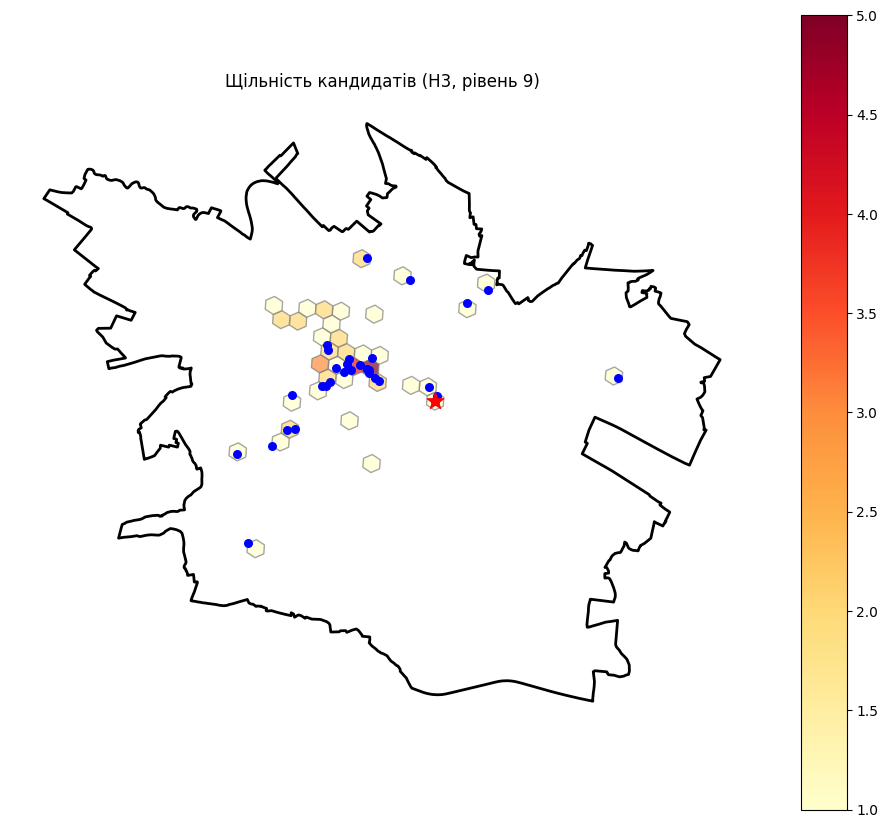

In [28]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))


repr_points = cand.geometry.representative_point()

cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in repr_points]

dens = cand.groupby('h3').size().reset_index(name='count')


hexes = gpd.GeoDataFrame(
    dens,
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(cell)]) for cell in dens['h3']],
    crs='EPSG:4326'
)

fig, ax = plt.subplots(figsize=(12, 12))

boundary.plot(ax=ax, color='none', edgecolor='black', linewidth=2, zorder=1) 

hexes.plot(ax=ax, column='count', cmap='YlOrRd', alpha=0.7, edgecolor='gray', legend=True, zorder=2)

pts_large.plot(ax=ax, color='blue', marker='o', markersize=30, zorder=3, label='Точки маршруту')

pts_large.head(1).plot(ax=ax, color='red', marker='*', markersize=150, zorder=4, label='Старт (Вокзал)')

plt.title(f'Щільність кандидатів (H3, рівень {H3_RES})')
plt.axis('off')
plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [29]:
pts_m = pts_large.to_crs(32635)
am_m = amenities.to_crs(32635)

joined = gpd.sjoin_nearest(pts_m, am_m, how='left', distance_col='distance_m')

result_table = joined[['name_left', 'name_right', 'distance_m']].copy()

result_table.columns = ['Точка маршруту', 'Найближчий заклад', 'Відстань (м)']
result_table['Відстань (м)'] = result_table['Відстань (м)'].round(1)

# Виводимо таблицю
display(result_table)

,Точка маршруту,Найближчий заклад,Відстань (м)
0,СТАРТ: Хмельницький,v-Victory-v,111.2
1,Хмельницький обласний художній музей,Dioscuri,43.3
2,Тарас Шевченко,HOME by Feelin’good,70.5
3,Вічний вогонь,Dioscuri,72.9
4,Ботанічний сад ХНУ,Мрія,176.4
5,Пам'ятник Богданові Хмельницькому,Домашня редакція,34.7
6,Богдан Хмельницький,Мрія,37.8
7,Музей історії міста Хмельницького,Barista Hub,65.1
8,Меморіал жертвам Голокосту,Оливкове кафе,643.9
9,Героям Небесної Сотні,Vinyl Coffee,48.6


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [30]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

import folium

BASEMAP = 'CartoDB positron' if 'BASEMAP' not in locals() else BASEMAP

D_large = road_matrix(ids_large)

start_tour = nearest_neighbour(D_large)

best_tour = two_opt(D_large, start_tour)

print(f"Довжина початкового маршруту: {tour_length(D_large, start_tour):.1f} м")
print(f"Довжина після оптимізації (best_tour): {tour_length(D_large, best_tour):.1f} м")

my_tour = best_tour 

road_path = route_coords(my_tour, ids_large)

straight_path = [(pts_large.geometry.iloc[i].y, pts_large.geometry.iloc[i].x) for i in my_tour]

start_lat = pts_large.geometry.iloc[my_tour[0]].y
start_lon = pts_large.geometry.iloc[my_tour[0]].x

fmap = folium.Map(location=[start_lat, start_lon], zoom_start=14, tiles=BASEMAP)

folium.PolyLine(
    straight_path,
    color='red',
    weight=2,
    dash_array='5, 5',
    opacity=0.7,
    tooltip='Пряма лінія (як летить птах)'
).add_to(fmap)

folium.PolyLine(
    road_path,
    color='blue',
    weight=4,
    opacity=0.8,
    tooltip='Реальний маршрут (по графу)'
).add_to(fmap)

for step, point_idx in enumerate(my_tour):

    if step == len(my_tour) - 1:
        break
        
    lat = pts_large.geometry.iloc[point_idx].y
    lon = pts_large.geometry.iloc[point_idx].x
    name = pts_large['name'].iloc[point_idx]
    
    html_icon = f"""
    <div style="background-color: white; border: 2px solid blue; border-radius: 50%; 
                width: 24px; height: 24px; text-align: center; line-height: 20px; 
                font-weight: bold; color: blue; font-size: 14px;">
        {step}
    </div>
    """
    
    folium.Marker(
        location=[lat, lon],
        popup=f"Крок {step}: {name}",
        tooltip=f"{step}. {name}",
        icon=folium.DivIcon(html=html_icon)
    ).add_to(fmap)

fmap.save('lr5_маршрут.html')

fmap

Довжина початкового маршруту: 33075.7 м
Довжина після оптимізації (best_tour): 30803.2 м


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [31]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (17.1 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [32]:
REPORT = '''
1. На кроці 2 було відкинуто 23 об'єкта. Замовнику не можна віддавати цей фільтр без пояснень, оскільки відсутність назви в базі OSM не завжди означає відсутність самого об'єкта.

2. У рейтинг увійшли три сигнали: наявність статті у Вікіпедії, кількість мов перекладу сторінки та площа об'єкта. Сигнали були нормалізовані через rank(pct=True) і зведені з вагами 0.4, 0.4,0.2, такі ваги обрано, бо перші два сигнали доволі показові, площа теж впливає, але не настільки сильно.

3. У двох рейтингах (наївний за площею та комплексний) із 10 об'єктів збіглося лише 3 об'єктів. Це означає, що поняття «найкращі» є абсолютно суб'єктивним і критично залежить від обраної метрики.

4. Коефіцієнт обходу склав 1.21. Типовий коефіцієнт для міст становить близько 1.2 – 1.4, тому наш коефіцієнт цілком вписується у ці межі.

5. Жадібний алгоритм «найближчого сусіда» виявився на 2.06% гіршим за оптимізований розв'язок (алгоритм 2-opt), що означає доволі хороший результат, це означає, що пам'ятки поставлені так, що поступовий прохід по найближчих пам'ятках дає хороший результат
6. Точний розв'язок (алгоритм Held-Karp) для нашої великої задачі (31 точка: вокзал + 30 пам'яток) недоступний через експоненційне зростання вимог до пам'яті. Побудова таблиці динамічного програмування для 31 точки вимагає понад 32,2 мільярда клітин, це займає рівно 240 ГБ оперативної пам'яті, що занадто багато для простого комп'ютеру та звичайного пошуку найшвидшого шляху.

7. У даних було виявлено пропущені назви, тому оскільки не було можливості встановити ці пам'ятки, було прийняте рішення їх видалити; дублікатів не було виявлено, лише об'єкти, які знаходяться дуже близько один до одного, проте вони були прив'язані до різних вузлів, тому з цим не було проблем.

Декларація про використання ШІ:
Під час виконання цієї лабораторної роботи я використовував Gemini. ШІ допоміг із: написанням функцій для роботи з NetworkX та GeoPandas, реалізацією евристичних алгоритмів (Nearest Neighbour, 2-opt), розрахунком метричних матриць відстаней, генерацією Folium-карти, а також надав пояснення математичних концепцій (detour factor, метод Held-Karp та H3-гексагони). Увесь згенерований код був проаналізований, зрозумітий мною та адаптований під специфіку моїх даних.
'''
print(REPORT)


1. На кроці 2 було відкинуто 23 об'єкта. Замовнику не можна віддавати цей фільтр без пояснень, оскільки відсутність назви в базі OSM не завжди означає відсутність самого об'єкта.

2. У рейтинг увійшли три сигнали: наявність статті у Вікіпедії, кількість мов перекладу сторінки та площа об'єкта. Сигнали були нормалізовані через rank(pct=True) і зведені з вагами 0.4, 0.4,0.2, такі ваги обрано, бо перші два сигнали доволі показові, площа теж впливає, але не настільки сильно.

3. У двох рейтингах (наївний за площею та комплексний) із 10 об'єктів збіглося лише 3 об'єктів. Це означає, що поняття «найкращі» є абсолютно суб'єктивним і критично залежить від обраної метрики.

4. Коефіцієнт обходу склав 1.21. Типовий коефіцієнт для міст становить близько 1.2 – 1.4, тому наш коефіцієнт цілком вписується у ці межі.

5. Жадібний алгоритм «найближчого сусіда» виявився на 2.06% гіршим за оптимізований розв'язок (алгоритм 2-opt), що означає доволі хороший результат, це означає, що пам'ятки поставлені т